# Tâche 3 : Question-réponse avec affinage par instructions du modèle pré-entraîné 

Cette tâche consiste à affiner par instructions le modèle pré-entraîné de la tâche 2 et d'évaluer la qualité de ses réponses. Vous utilisez les mêmes paires **question-réponse** que celles des tâches précentes. Le fichier d'**instructions** pour l'affinage du modèle est également fourni dans le répertoire *data*. 

> Il est recommandé de faire ce travail pratique en utilisant une carte graphique GPU compatible avec HuggingFace/Pytorch.
> Si votre machine n’en possède pas, vous pouvez utiliser **Google Colab** pour exécuter le *notebook* dans le cloud.

## 1. Chargement du modèle Hugging Face et du tokenizer

In [1]:
import torch
import transformers

print("PyTorch :", torch.__version__)
print("Transformers :", transformers.__version__)
print("GPU disponible :", torch.cuda.is_available())
print("GPU :", torch.cuda.get_device_name(0))

PyTorch : 2.14.1+cu130
Transformers : 5.18.0
GPU disponible : True
GPU : NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [ ]:

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

chemin_model = "pythia-410m-t2"

tokenizer = AutoTokenizer.from_pretrained(
    chemin_model,
    local_files_only=True
)

tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    chemin_model,
    dtype=torch.float32,
    local_files_only=True
)

model.config.pad_token_id = tokenizer.pad_token_id

print("Modèle disponible :", model is not None)
print("Précision des poids :", next(model.parameters()).dtype)
print("Appareil actuel :", next(model.parameters()).device)
print("Nombre de paramètres :", sum(p.numel() for p in model.parameters()))


Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

Modèle disponible : True
Précision des poids : torch.float32
Appareil actuel : cpu
Nombre de paramètres : 405334016


## 2. Fonctions de test question-réponse 

In [16]:
def build_prompt(question):
    """Construit le prompt à partir d'une question."""
    return f"Question: {question}\nAnswer:"

In [17]:
def generate_answer(question, model, tokenizer, max_new_tokens=100):
    """Génère une réponse et retourne uniquement le texte produit après le prompt."""
    prompt = build_prompt(question)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False, # décodage glouton : résultats reproductibles
            repetition_penalty=1.2, # limite les boucles de répétition
            pad_token_id=tokenizer.eos_token_id,
        )
    # On garde seulement les nouveaux jetons (sans prompt)
    new_tokens = output_ids[0][inputs["input_ids"].shape[1]:]
    answer = tokenizer.decode(new_tokens, skip_special_tokens=True)
    # On coupe si le modèle enchaîne sur une nouvelle question
    answer = answer.split("\nQuestion:")[0].split("\n\n")[0]
    return answer.strip()

In [18]:
q = "What is Mixture of Experts (MoE) and what type of machine learning technique is it?"
print("Q :", q)
print("R :", generate_answer(q, model, tokenizer))

Q : What is Mixture of Experts (MoE) and what type of machine learning technique is it?
R : Mixture of experts (MoE) is a supervised learning algorithm that uses multiple experts to learn from data. It can be used for classification, regression or clustering tasks.


## 3. Affinage du modèle par instructions

In [15]:
import json

train_fn = "data/alpaca_data.json"

with open(train_fn, "r", encoding="utf-8") as f:
    train_data = json.load(f)

In [16]:
from datasets import Dataset

dataset_texte = Dataset.from_dict({
    "instruction": [item["instruction"] for item in train_data],
    "input": [item["input"] for item in train_data],
    "output": [item["output"] for item in train_data]
})

dict_split_dataset = dataset_texte.train_test_split(
    test_size=0.1,
    seed=20
)

print(dict_split_dataset)

DatasetDict({
    train: Dataset({
        features: ['instruction', 'input', 'output'],
        num_rows: 6300
    })
    test: Dataset({
        features: ['instruction', 'input', 'output'],
        num_rows: 700
    })
})


In [17]:
def tokenize_function(examples):
    input_ids = []
    attention_masks = []
    labels = []

    for instruction, entree, reponse in zip(
        examples["instruction"],
        examples["input"],
        examples["output"]
    ):
        question = instruction.strip()

        if entree.strip():
            question += "\n" + entree.strip()

        prompt = build_prompt(question)

        tokens_prompt = tokenizer(
            prompt,
            add_special_tokens=False
        )["input_ids"]

        tokens_reponse = tokenizer(
            " " + reponse.strip(),
            add_special_tokens=False
        )["input_ids"]

        tokens_reponse.append(tokenizer.eos_token_id)

        ids = tokens_prompt + tokens_reponse

        input_ids.append(ids)
        attention_masks.append([1] * len(ids))
        labels.append(
            [-100] * len(tokens_prompt) + tokens_reponse.copy()
        )

    return {
        "input_ids": input_ids,
        "attention_mask": attention_masks,
        "labels": labels
    }

In [18]:
dataset_texte_tokenized = dict_split_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["instruction", "input", "output"]
)

print(dataset_texte_tokenized)

Map:   0%|          | 0/6300 [00:00<?, ? examples/s]

Map:   0%|          | 0/700 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 6300
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 700
    })
})


In [19]:
exemple = dataset_texte_tokenized["train"][0]

print("Nombre de tokens :", len(exemple["input_ids"]))
print("Nombre de -100 :", exemple["labels"].count(-100))

print("\nPROMPT MASQUÉ :")
print(tokenizer.decode([
    token for token, label in zip(
        exemple["input_ids"], exemple["labels"]
    ) if label == -100
]))

print("\nRÉPONSE À APPRENDRE :")
print(tokenizer.decode([
    token for token, label in zip(
        exemple["input_ids"], exemple["labels"]
    ) if label != -100
]))

Nombre de tokens : 28
Nombre de -100 : 17

PROMPT MASQUÉ :
Question: Provide antonyms for the word 'evil'.
Answer:

RÉPONSE À APPRENDRE :
 Good, righteous, just, divine, upright.<|endoftext|>


In [20]:
def data_collator(features):
    # Trouver la longueur maximale du lot
    longueur_max = max(len(f["input_ids"]) for f in features)

    input_ids = []
    attention_masks = []
    labels = []

    for f in features:
        # Calculer le nombre de tokens à ajouter
        n_padding = longueur_max - len(f["input_ids"])

        # Ajouter le padding aux input_ids
        input_ids.append(
            f["input_ids"] + [tokenizer.pad_token_id] * n_padding
        )

        # Les positions de padding reçoivent 0
        attention_masks.append(
            f["attention_mask"] + [0] * n_padding
        )

        # Ignorer le padding dans le calcul de la perte
        labels.append(
            f["labels"] + [-100] * n_padding
        )

    # Transformer les listes en tenseurs PyTorch
    return {
        "input_ids": torch.tensor(input_ids, dtype=torch.long),
        "attention_mask": torch.tensor(attention_masks, dtype=torch.long),
        "labels": torch.tensor(labels, dtype=torch.long)
    }


In [ ]:
# Hyperparamètres à comparer
batch_sizes = [4, 8, 16]
learning_rates = [1e-5, 2e-5, 5e-5]
nombre_epoques = 3
seed = 20

# Première configuration à tester
batch_size = batch_sizes[0]
learning_rate = learning_rates[0]

print("Batch size :", batch_size)
print("Learning rate :", learning_rate)
print("Nombre d'époques :", nombre_epoques)


Batch size : 4
Learning rate : 0.0001
Nombre d'époques : 3


In [22]:
block_size = 256

longueurs = [
    len(exemple["input_ids"])
    for exemple in dataset_texte_tokenized["train"]
]

print("Longueur maximale :", max(longueurs))
print("Longueur moyenne :", sum(longueurs) / len(longueurs))
print("Exemples dépassant 256 tokens :", sum(l > block_size for l in longueurs))
print("Pourcentage :", round(100 * sum(l > block_size for l in longueurs) / len(longueurs), 2), "%")

dataset_texte_tokenized = dataset_texte_tokenized.filter(
    lambda exemple: len(exemple["input_ids"]) <= block_size
)

print(dataset_texte_tokenized)

Longueur maximale : 621
Longueur moyenne : 65.5552380952381
Exemples dépassant 256 tokens : 24
Pourcentage : 0.38 %


Filter:   0%|          | 0/6300 [00:00<?, ? examples/s]

Filter:   0%|          | 0/700 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 6276
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 699
    })
})


In [23]:
for batch_size in [4, 8]:
    exemples = [
        dataset_texte_tokenized["train"][i]
        for i in range(batch_size)
    ]

    batch = data_collator(exemples)

    print(f"\nBatch size : {batch_size}")
    print("Dimensions :", batch["input_ids"].shape)
    print("Padding :", (batch["attention_mask"] == 0).sum().item())

    assert batch["input_ids"].shape[0] == batch_size
    assert torch.all(batch["labels"][batch["attention_mask"] == 0] == -100)



Batch size : 4
Dimensions : torch.Size([4, 90])
Padding : 128

Batch size : 8
Dimensions : torch.Size([8, 117])
Padding : 346


In [15]:
import time
import gc
import torch
from transformers import AutoModelForCausalLM, Trainer, TrainingArguments

resultats = []
historiques = {}

# Libérer le modèle du premier essai
trainer = None
gc.collect()
torch.cuda.empty_cache()


for batch_size in batch_sizes:
    for learning_rate in learning_rates:

        nom_essai = f"b{batch_size}_lr{learning_rate:.1e}"
        print(f"\n===== Entraînement : {nom_essai} =====")

        # Repartir des poids originaux de Q2
        modele_essai = AutoModelForCausalLM.from_pretrained(
            chemin_model,
            dtype=torch.float32,
            local_files_only=True
        )
        modele_essai.config.pad_token_id = tokenizer.pad_token_id

        # Configuration de l'essai
        training_args = TrainingArguments(
            output_dir=f"t3_checkpoints/{nom_essai}",
            save_total_limit=1,
            num_train_epochs=nombre_epoques,
            learning_rate=learning_rate,
            per_device_train_batch_size=batch_size,
            per_device_eval_batch_size=16,
            eval_strategy="epoch",
            save_strategy="epoch",
            load_best_model_at_end=True,
            metric_for_best_model="eval_loss",
            greater_is_better=False,
            fp16=torch.cuda.is_available(),
            logging_steps=20,
            report_to="none",
            seed=seed
        )

        trainer = Trainer(
            model=modele_essai,
            args=training_args,
            train_dataset=dataset_texte_tokenized["train"],
            eval_dataset=dataset_texte_tokenized["test"],
            data_collator=data_collator
        )

        # Mesurer la perte initiale
        loss_initiale = trainer.evaluate()["eval_loss"]

        # Entraînement des 3 époques    
        debut = time.perf_counter()

        trainer.train()

        temps_entrainement = time.perf_counter() - debut

        # Conserver les résultats
        resultats.append({
            "nom_essai": nom_essai,
            "batch_size": batch_size,
            "learning_rate": learning_rate,
            "loss_initiale": loss_initiale,
            "meilleure_loss": trainer.state.best_metric,
            "temps_secondes": round(temps_entrainement, 2),
            "temps_minutes": round(temps_entrainement / 60, 2),
            "checkpoint": trainer.state.best_model_checkpoint
        })

        print("Meilleure loss :", trainer.state.best_metric)
        print(f"Temps d'entraînement : {round(temps_entrainement, 2)} secondes")

        # Libérer la mémoire GPU avant l'essai suivant
        historiques[nom_essai] = trainer.state.log_history
        del trainer
        del modele_essai
        gc.collect()
        torch.cuda.empty_cache()



===== Entraînement : b4_lr1.0e-04 =====


Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch
No log,2.139838,0


Epoch,Training Loss,Validation Loss
1,3.071664,2.992713
2,1.989540,2.835690
3,0.989889,2.837653


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (119 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['lm_head.weight'].
[transformers] There were unexpected keys in the checkpoint model loaded: ['embed_out.weight'].


Meilleure loss : 1.8360450267791748
Temps d'entraînement : 829.57 secondes


In [16]:
import re
import pandas as pd

df_resultats = pd.DataFrame(resultats)

df_resultats["meilleure_epoque"] = df_resultats.apply(
    lambda ligne: int(re.search(r"checkpoint-(\d+)", ligne["checkpoint"]).group(1))
    / ((len(dataset_texte_tokenized["train"]) + ligne["batch_size"] - 1) // ligne["batch_size"]),
    axis=1
)

display(
    df_resultats[
        ["batch_size", "learning_rate", "meilleure_epoque",
         "meilleure_loss", "temps_minutes", "checkpoint"]
    ].sort_values("meilleure_loss")
)

,batch_size,learning_rate,meilleure_epoque,meilleure_loss,temps_minutes,checkpoint
13,24,0.00001,1.0,1.630515,13.04,t3_checkpoints/b24_lr1.0e-05\checkpoint-262
9,16,0.00001,1.0,1.636348,5.18,t3_checkpoints/b16_lr1.0e-05\checkpoint-393
5,8,0.00001,1.0,1.656235,67.94,t3_checkpoints/b8_lr1.0e-05\checkpoint-785
14,24,0.00002,1.0,1.667516,13.16,t3_checkpoints/b24_lr2.0e-05\checkpoint-262
1,4,0.00001,1.0,1.689158,9.03,t3_checkpoints/b4_lr1.0e-05\checkpoint-1569
10,16,0.00002,1.0,1.690079,5.36,t3_checkpoints/b16_lr2.0e-05\checkpoint-393
6,8,0.00002,1.0,1.744481,7.42,t3_checkpoints/b8_lr2.0e-05\checkpoint-785
2,4,0.00002,1.0,1.824807,8.28,t3_checkpoints/b4_lr2.0e-05\checkpoint-1569
15,24,0.00005,1.0,1.836045,13.83,t3_checkpoints/b24_lr5.0e-05\checkpoint-262
11,16,0.00005,1.0,1.896665,5.03,t3_checkpoints/b16_lr5.0e-05\checkpoint-393


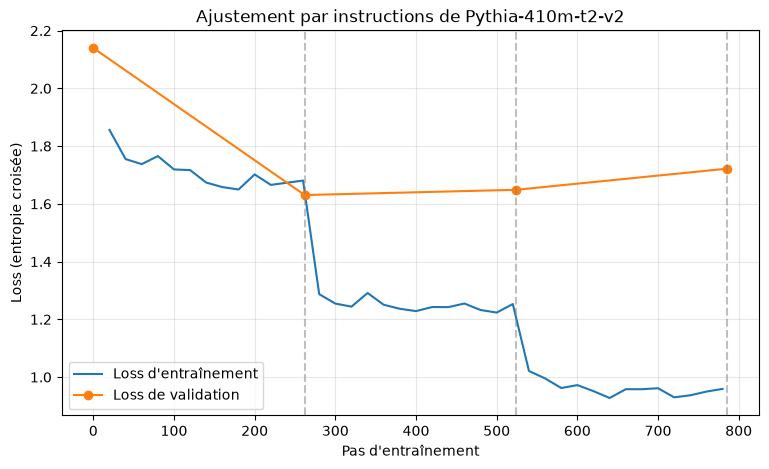

In [ ]:
import matplotlib.pyplot as plt

meilleur = df_resultats.sort_values("meilleure_loss").iloc[0]
historique = historiques[meilleur["nom_essai"]]

logs_train = [d for d in historique if "loss" in d]
logs_eval = [d for d in historique if "eval_loss" in d]

steps_train = [d["step"] for d in logs_train]
loss_train = [d["loss"] for d in logs_train]

steps_eval = [0] + [d["step"] for d in logs_eval]
loss_eval = [meilleur["loss_initiale"]] + [d["eval_loss"] for d in logs_eval]

plt.figure(figsize=(9, 5))
plt.plot(steps_train, loss_train, label="Loss d'entraînement")
plt.plot(steps_eval, loss_eval, marker="o", label="Loss de validation")

# Délimitation des époques
taille_lot = int(meilleur["batch_size"])
steps_par_epoque = (len(dataset_texte_tokenized["train"]) + taille_lot - 1) // taille_lot

for epoque in range(1, nombre_epoques + 1):
    plt.axvline(epoque * steps_par_epoque, color="gray", linestyle="--", alpha=0.5)

plt.xlabel("Pas d'entraînement")
plt.ylabel("Loss (entropie croisée)")
plt.title("Ajustement par instructions de Pythia-410m-t2")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 4. Génération des réponses aux questions avec le modèle

In [ ]:
test_fn = "data/test_questions.json"

# Charger le meilleur modèle affiné
meilleur_checkpoint = df_resultats.sort_values("meilleure_loss").iloc[0]["checkpoint"]
print("Meilleur checkpoint :", meilleur_checkpoint)

model = AutoModelForCausalLM.from_pretrained(
    meilleur_checkpoint,
    dtype=torch.float16,
    local_files_only=True
).to("cuda")

# L'enregistrer pour T4
chemin_t3 = "pythia-410m-t3"

model.save_pretrained(chemin_t3)
tokenizer.save_pretrained(chemin_t3)

print("Modèle et tokenizer enregistrés dans", chemin_t3)

Meilleur checkpoint : t3_checkpoints/b24_lr1.0e-05/checkpoint-262


Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modèle et tokenizer enregistrés dans pythia-410m-t3


In [20]:
from tqdm.auto import tqdm

with open(test_fn, "r", encoding="utf-8") as f:
    test_data = json.load(f)
print(f"{len(test_data)} questions chargées")

model.eval()
results = []
for item in tqdm(test_data):
    generated = generate_answer(item["question"], model, tokenizer)
    results.append({
        "question": item["question"],
        "reference": item["answer"],
        "generated": generated,
    })

# Aperçu des 3 premières réponses
for r in results[:3]:
    print("Q :", r["question"])
    print("R :", r["generated"])
    print("-" * 80)

50 questions chargées


  0%|          | 0/50 [00:00<?, ?it/s]

Q : What is the context window size of GPT-3?
R : The context window size for GPT-3 is 64,000.
--------------------------------------------------------------------------------
Q : Explain what is a transformer architecture.
R : A transformer architecture is an artificial neural network that takes input data and produces output data, such as text or images. It uses layers of neurons to process the incoming data into a sequence of vectors which are then used for classification tasks like image recognition or speech recognition.
--------------------------------------------------------------------------------
Q : Define what is a generative pre-trained transformer (GPT).
R : A generative pre-trained transformer (GPT) is an artificial neural network that takes input data and produces output. It can be used to generate text from images, audio or video content. GPTs are often used in natural language processing tasks such as machine translation, sentiment analysis, and image recognition.
----

In [21]:
from pathlib import Path

Path("results").mkdir(exist_ok=True)

output_fn = "results/t3_answers.json"

with open(output_fn, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

print("Réponses sauvegardées dans", output_fn)

Réponses sauvegardées dans results/t3_answers.json


 ## 5. Évaluation des résultats 

In [22]:
import string
import re
from collections import Counter

def remove_articles(text):
    return re.sub(r'\b(a|an|the)\b', ' ', text)

def white_space_fix(text):
    return ' '.join(text.split())

def remove_punc(text):
    exclude = set(string.punctuation)
    return ''.join(ch for ch in text if ch not in exclude)

def lower(text):
    return text.lower()

def normalize_answer(s):
    """Mettre en minuscule et retirer la ponctuation, des déterminants and les espaces."""
    return white_space_fix(remove_articles(remove_punc(lower(s))))

In [23]:
def evaluate_f1(ground_truth, prediction):
    """Normalise les 2 textes, trouve ce qu'il y a en commun et estime précision, rappel et F1."""
    prediction_tokens = normalize_answer(prediction).split()
    ground_truth_tokens = normalize_answer(ground_truth).split()
    common = Counter(prediction_tokens) & Counter(ground_truth_tokens)
    num_same = sum(common.values())
    if num_same == 0:
        return 0.0, 0.0, 0.0
    precision = 1.0 * num_same / len(prediction_tokens)
    recall = 1.0 * num_same / len(ground_truth_tokens)
    f1 = (2 * precision * recall) / (precision + recall)
    return precision, recall, f1

In [24]:
import pandas as pd

for r in results:
    p, rc, f1 = evaluate_f1(r["reference"], r["generated"])
    r["precision"], r["recall"], r["f1"] = p, rc, f1

df = pd.DataFrame(results)
pd.set_option("display.max_colwidth", 80)
df[["question", "generated", "precision", "recall", "f1"]]

,question,generated,precision,recall,f1
0,What is the context window size of GPT-3?,"The context window size for GPT-3 is 64,000.",0.571429,0.500000,0.533333
1,Explain what is a transformer architecture.,A transformer architecture is an artificial neural network that takes input ...,0.155556,0.318182,0.208955
2,Define what is a generative pre-trained transformer (GPT).,A generative pre-trained transformer (GPT) is an artificial neural network t...,0.217391,0.333333,0.263158
3,Which sources comprise the weighted pre-training dataset for GPT-3?,The weighted pre-trained dataset used in this study is composed of a collect...,0.045455,0.071429,0.055556
4,List the three main classes of language modelling tasks discussed in the con...,"The three main classes of language modeling tasks are text classification, n...",0.352941,0.666667,0.461538
5,What is knowledge distillation in the context of transformer models?,"Knowledge distillation (also known as ""knowledge distillation"") is a techniq...",0.140351,0.258065,0.181818
6,What is GPT-4 and who developed it?,GPT-4 was created by the Google Brain team in 2017. It uses natural language...,0.166667,0.294118,0.212766
7,In what year was GPT-4 released in ChatGPT?,GPT-4 is available for download on the Google Play Store and Apple AppStore.,0.083333,0.142857,0.105263
8,Describe what is multimodal capability in the context of GPT-4?,"Multimodal capabilities include natural language processing, machine transla...",0.181818,0.076923,0.108108
9,On what date was GPT-4 training completed?,"GPT-4 training began on August 20, 2017.",0.571429,0.571429,0.571429


In [25]:
print("Moyennes sur", len(df), "questions")
print("="*25)
print(f"Précision : {df['precision'].mean():.3f}")
print(f"Rappel    : {df['recall'].mean():.3f}")
print(f"F1        : {df['f1'].mean():.3f}")
print("Réponses avec un F1 de 0 :", (df["f1"] == 0).sum())


Moyennes sur 50 questions
Précision : 0.200
Rappel    : 0.291
F1        : 0.220
Réponses avec un F1 de 0 : 1


In [26]:
print("\n 3 meilleures réponses (F1)")
print("="*25)
for _, r in df.nlargest(3, "f1").iterrows():
    print(f"[F1={r['f1']:.2f}] Q : {r['question']}")
    print("   Réf :", r["reference"])
    print("   Gén :", r["generated"], "\n")

print("3 pires réponses (F1)")
print("="*25)
for _, r in df.nsmallest(3, "f1").iterrows():
    print(f"[F1={r['f1']:.2f}] Q : {r['question']}")
    print("   Réf :", r["reference"])
    print("   Gén :", r["generated"], "\n")


 3 meilleures réponses (F1)
[F1=0.57] Q : On what date was GPT-4 training completed?
   Réf : GPT-4 finished training on August 8th, 2022.
   Gén : GPT-4 training began on August 20, 2017. 

[F1=0.53] Q : What is the context window size of GPT-3?
   Réf : GPT-3 has a context window size of 2,048 tokens.
   Gén : The context window size for GPT-3 is 64,000. 

[F1=0.46] Q : List the three main classes of language modelling tasks discussed in the context of transformers?
   Réf : The three main classes are masked, autoregressive, and prefixLM tasks.
   Gén : The three main classes of language modeling tasks are text classification, natural language processing (NLM), and machine translation. 

3 pires réponses (F1)
[F1=0.00] Q : When was the first version of Gemma released?
   Réf : February 2024
   Gén : The first version of Gemma, released in 2013, is a free and open-source project. 

[F1=0.05] Q : What architectural change was made in the Llama 4 series?
   Réf : The architecture was c

### Comparaison avec la tâche 2

In [27]:
import os
import json

# Réponses de la tâche 3 (déjà générées et enregistrées)
with open("results/t3_answers.json", "r", encoding="utf-8") as f:
    results = json.load(f)

for r in results:
    p, rc, f1 = evaluate_f1(r["reference"], r["generated"])
    r["precision"], r["recall"], r["f1"] = p, rc, f1

df = pd.DataFrame(results)
print(len(df), "réponses T3 chargées")

# Réponses générées par le modèle de la tâche 2
t2_fn = "results/t2_answers.json"
print("Fichier T2 trouvé :", os.path.exists(t2_fn))

with open(t2_fn, "r", encoding="utf-8") as f:
    results_t2 = json.load(f)

for r in results_t2:
    p, rc, f1 = evaluate_f1(r["reference"], r["generated"])
    r["precision"], r["recall"], r["f1"] = p, rc, f1

df_t2 = pd.DataFrame(results_t2)


assert list(df_t2["question"]) == list(df["question"]), "Les questions T2 et T3 ne correspondent pas!"
print(len(df_t2), "réponses T2 chargées")

50 réponses T3 chargées
Fichier T2 trouvé : True
50 réponses T2 chargées


In [28]:
import pandas as pd

# 1. Moyennes côte à côte
moyennes = pd.DataFrame({
    "T2 (préentraînement)": df_t2[["precision", "recall", "f1"]].mean(),
    "T3 (instructions)": df[["precision", "recall", "f1"]].mean(),
})
moyennes["Différence"] = moyennes.iloc[:, 1] - moyennes.iloc[:, 0]
print("Moyennes sur", len(df), "questions")
print("=" * 25)
print(moyennes.round(3), "\n")

# 2. Différence de F1 question par question
df_comp = pd.DataFrame({
    "question":  df["question"],
    "reference": df["reference"],
    "gen_t2":    df_t2["generated"],
    "gen_t3":    df["generated"],
    "f1_t2":     df_t2["f1"],
    "f1_t3":     df["f1"],
})
df_comp["delta_f1"] = df_comp["f1_t3"] - df_comp["f1_t2"]

print("Questions améliorées :", (df_comp["delta_f1"] > 0).sum())
print("Questions dégradées  :", (df_comp["delta_f1"] < 0).sum())
print("Questions identiques :", (df_comp["delta_f1"] == 0).sum())


def afficher(lignes, titre):
    print("\n" + titre)
    print("=" * 25)
    for _, r in lignes.iterrows():
        print(f"[ΔF1={r['delta_f1']:+.2f}] Q : {r['question']}")
        print("   Réf :", r["reference"])
        print(f"   T2 (F1={r['f1_t2']:.2f}) :", r["gen_t2"])
        print(f"   T3 (F1={r['f1_t3']:.2f}) :", r["gen_t3"], "\n")

afficher(df_comp.nlargest(3, "delta_f1"),  "3 plus grandes progressions")
afficher(df_comp.nsmallest(3, "delta_f1"), "3 plus grandes régressions")

df_comp.to_csv("results/t3_comparaison_t2.csv", index=False)

Moyennes sur 50 questions
           T2 (préentraînement)  T3 (instructions)  Différence
precision                 0.079              0.200       0.121
recall                    0.305              0.291      -0.015
f1                        0.120              0.220       0.101 

Questions améliorées : 40
Questions dégradées  : 9
Questions identiques : 1

3 plus grandes progressions
[ΔF1=+0.55] Q : On what date was GPT-4 training completed?
   Réf : GPT-4 finished training on August 8th, 2022.
   T2 (F1=0.02) : The first day of the month. It is not clear whether this occurred on a specific day or over time, but it seems likely that it did occur at some point during the week. This would be consistent with previous research suggesting that humans are able to recall dates and times from memory even when they have no recollection of them (see "Memory for Time" in Chapter 3). In addition, human experts can remember events without having any prior knowledge about those events (e.g., by learni

In [29]:
# Scores globaux
f1 = df["f1"]
print(f"Précision {df['precision'].mean():.3f} | Rappel {df['recall'].mean():.3f} | "
      f"F1 moyen {f1.mean():.3f} | F1 médian {f1.median():.3f} | "
      f"F1 = 0 : {(f1 == 0).sum()}/50 | F1 >= 0,2 : {(f1 >= 0.2).sum()}/50 | max {f1.max():.3f}")

# Classement manuel par type (indices 0 à 49) et longueur de réponse
types = {
    "Définition / concept": [1, 2, 5, 6, 8, 12, 18, 19, 21, 25, 30, 32, 36, 38, 39, 40, 42, 43, 44, 45, 49],
    "Fait précis (date, chiffre, nom)": [0, 7, 9, 10, 13, 14, 20, 23, 24, 28, 31, 33, 35, 37, 46],
    "Énumération / liste": [3, 4, 11, 15, 16, 17, 22, 26, 27, 29, 34, 41, 47, 48],
}
df["groupe"] = pd.Series({i: t for t, idx in types.items() for i in idx})
df["longueur"] = df["generated"].str.len().le(80).map({True: "Courte (≤ 80 car.)", False: "Longue"})

agg = dict(n=("f1", "size"), precision=("precision", "mean"), rappel=("recall", "mean"),
           f1=("f1", "mean"), f1_nul=("f1", lambda s: (s == 0).sum()))
display(pd.concat([df.groupby("groupe").agg(**agg), df.groupby("longueur").agg(**agg)]).round(3))

# Exemples (3 meilleures réponses)
display(df.nlargest(3, "f1")[["question", "reference", "generated", "f1"]])

Précision 0.200 | Rappel 0.291 | F1 moyen 0.220 | F1 médian 0.212 | F1 = 0 : 1/50 | F1 >= 0,2 : 29/50 | max 0.571


,n,precision,rappel,f1,f1_nul
Définition / concept,21,0.199,0.301,0.231,0
"Fait précis (date, chiffre, nom)",15,0.241,0.263,0.232,1
Énumération / liste,14,0.158,0.304,0.193,0
Courte (≤ 80 car.),9,0.297,0.264,0.267,1
Longue,41,0.179,0.296,0.210,0


,question,reference,generated,f1
9,On what date was GPT-4 training completed?,"GPT-4 finished training on August 8th, 2022.","GPT-4 training began on August 20, 2017.",0.571429
0,What is the context window size of GPT-3?,"GPT-3 has a context window size of 2,048 tokens.","The context window size for GPT-3 is 64,000.",0.533333
4,List the three main classes of language modelling tasks discussed in the con...,"The three main classes are masked, autoregressive, and prefixLM tasks.","The three main classes of language modeling tasks are text classification, n...",0.461538
